In [36]:
import pandas as pd
import json                                                     # 추가

en = pd.read_csv('data/processed/en/processed_en.csv')          # 경로 변경
en = en.dropna(subset=['tokens'])
texts_en = en['tokens'].str.split().tolist()

In [37]:
from gensim.corpora.dictionary import Dictionary

dictionary = Dictionary(texts_en)
print('#Number of initial unique words in documents:', len(dictionary))

dictionary.filter_extremes(keep_n = None, no_below=2, no_above=0.5)
print('#Number of unique words after removing rare and common words:', len(dictionary))

corpus = [dictionary.doc2bow(text) for text in texts_en]
print('#Number of unique tokens: %d' % len(dictionary))
print('#Number of documents: %d' % len(corpus))

#Number of initial unique words in documents: 11596
#Number of unique words after removing rare and common words: 6355
#Number of unique tokens: 6355
#Number of documents: 800


In [38]:
from gensim.models import LdaModel

num_topics = 9
passes = 5
%time model = LdaModel(corpus=corpus, id2word=dictionary,\
                       passes=passes, num_topics=num_topics, \
                       random_state=7)

CPU times: total: 7 s
Wall time: 7.26 s


In [39]:
model.print_topics(num_words=10)

[(0,
  '0.016*"tour" + 0.015*"ticket" + 0.012*"award" + 0.009*"world" + 0.009*"concert" + 0.007*"good" + 0.006*"artist" + 0.006*"pm" + 0.006*"billboard" + 0.005*"hit"'),
 (1,
  '0.008*"love" + 0.007*"korean" + 0.007*"track" + 0.005*"south" + 0.005*"work" + 0.005*"world" + 0.005*"performance" + 0.005*"debut" + 0.005*"korea" + 0.004*"scoups"'),
 (2,
  '0.013*"love" + 0.009*"mina" + 0.006*"fashion" + 0.005*"seungkwan" + 0.004*"track" + 0.004*"good" + 0.004*"jeongyeon" + 0.004*"day" + 0.004*"company" + 0.003*"south"'),
 (3,
  '0.009*"south" + 0.009*"korean" + 0.008*"korea" + 0.007*"military" + 0.007*"jin" + 0.006*"world" + 0.006*"tour" + 0.006*"big" + 0.005*"service" + 0.004*"hit"'),
 (4,
  '0.027*"chart" + 0.015*"billboard" + 0.013*"debut" + 0.010*"world" + 0.010*"week" + 0.009*"artist" + 0.008*"sale" + 0.007*"act" + 0.007*"ddu" + 0.007*"du"'),
 (5,
  '0.010*"post" + 0.008*"entertainment" + 0.008*"artist" + 0.006*"korean" + 0.006*"star" + 0.005*"agency" + 0.005*"test" + 0.005*"statement" 

In [40]:
print("#topic distribution of the first document: ", model.get_document_topics(corpus)[0])

#topic distribution of the first document:  [(4, 0.47861102), (6, 0.5127377)]


In [41]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis
pyLDAvis.enable_notebook()

lda_viz = gensimvis.prepare(model, corpus, dictionary)
lda_viz

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
1     -0.025107  0.064148       1        1  18.432641
3     -0.005599  0.002797       2        1  14.284786
8     -0.001059  0.027429       3        1  13.302336
0      0.060452  0.010782       4        1  11.117702
4      0.074348 -0.043323       5        1  10.790391
7     -0.027589 -0.043748       6        1  10.761851
5     -0.080011 -0.098987       7        1  10.741243
6      0.092224  0.012170       8        1   6.778680
2     -0.087658  0.068732       9        1   3.790371, topic_info=             Term        Freq       Total Category  logprob  loglift
6           chart  719.000000  719.000000  Default  30.0000  30.0000
1404       ticket  286.000000  286.000000  Default  29.0000  29.0000
30           love  666.000000  666.000000  Default  28.0000  28.0000
519     billboard  545.000000  545.000000  Default  27.0000  27.0000
552          sale  320.000000  320.000000  Default  26.0000  26.0000
...           ...         ...         ...      ...      ...      ...
269       include   15.398893  446.553191   Topic9  -5.8644  -0.0946
6112        jihyo   14.034327  203.944687   Topic9  -5.9572   0.5964
1094        share   14.869500  422.205172   Topic9  -5.8994  -0.0735
235   performance   14.892506  459.777608   Topic9  -5.8979  -0.1572
211         award   14.210369  352.452976   Topic9  -5.9448   0.0618

[738 rows x 6 columns], token_table=      Topic      Freq     Term
term                          
6323      1  0.152748  aboutzu
6323      3  0.763739  aboutzu
1958      1  0.072720   accept
1958      2  0.145440   accept
1958      3  0.181800   accept
...     ...       ...      ...
473       9  0.013332  youtube
5056      6  0.846949  zionist
2261      3  0.054227      zoo
2261      6  0.108453      zoo
2261      7  0.759174      zoo

[2660 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[2, 4, 9, 1, 5, 8, 6, 7, 3])

In [42]:
from gensim.models import CoherenceModel

cm = CoherenceModel(model=model, corpus=corpus, coherence='u_mass')
coherence = cm.get_coherence()
print(coherence)

-1.559130663383275


In [43]:
import matplotlib.pyplot as plt
%matplotlib inline

num_topics: 2, perplexity: -7.756, coherence: -1.009
num_topics: 3, perplexity: -7.797, coherence: -1.034
num_topics: 4, perplexity: -7.845, coherence: -1.053
num_topics: 5, perplexity: -7.892, coherence: -1.033
num_topics: 6, perplexity: -7.931, coherence: -1.058
num_topics: 7, perplexity: -7.979, coherence: -1.055
num_topics: 8, perplexity: -8.025, coherence: -1.047
num_topics: 9, perplexity: -8.075, coherence: -1.024
num_topics: 10, perplexity: -8.121, coherence: -1.075
num_topics: 11, perplexity: -8.165, coherence: -1.072
num_topics: 12, perplexity: -8.216, coherence: -1.122
num_topics: 13, perplexity: -8.253, coherence: -1.111
num_topics: 14, perplexity: -8.295, coherence: -1.110
num_topics: 15, perplexity: -8.336, coherence: -1.164


c:\Users\ljmm5\anaconda3\envs\nlp\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


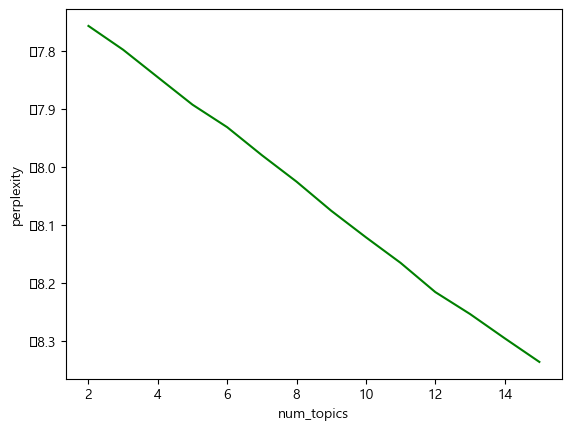

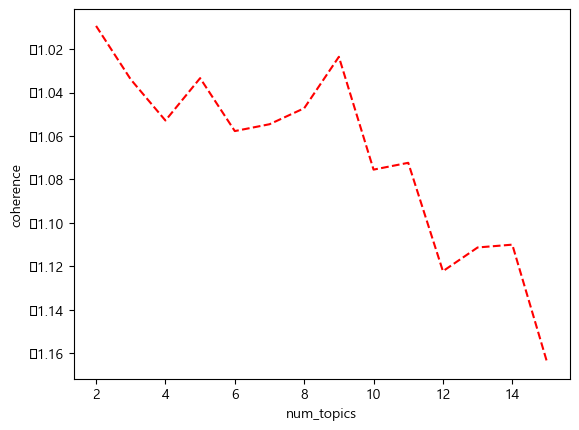

In [44]:
def show_coherence(corpus, dictionary, start=6, end=15):
    iter_num = []
    per_value = []
    coh_value = []

    for i in range(start, end + 1):
        model = LdaModel(corpus=corpus, id2word=dictionary,
                         chunksize=1000, num_topics=i,
                         random_state=7)
        iter_num.append(i)
        pv = model.log_perplexity(corpus)
        per_value.append(pv)

        cm = CoherenceModel(model=model, corpus=corpus,
                            coherence='u_mass')
        cv = cm.get_coherence()
        coh_value.append(cv)
        print(f'num_topics: {i}, perplexity: {pv:0.3f}, coherence: {cv:0.3f}')

    plt.plot(iter_num, per_value, 'g-')
    plt.xlabel("num_topics")
    plt.ylabel("perplexity")
    plt.show()

    plt.plot(iter_num, coh_value, 'r--')
    plt.xlabel("num_topics")
    plt.ylabel("coherence")
    plt.show()

show_coherence(corpus, dictionary, start=2, end=15)

In [52]:
from gensim.matutils import corpus2dense

pet_topics = corpus2dense(model.get_document_topics(corpus, minimum_probability=0),
                          num_terms=num_topics).T

trend_data = pd.DataFrame(pet_topics, columns=['Topic'+str(i) for i in range(1, num_topics + 1)])
trend_data = pd.concat([trend_data, en['group'].reset_index(drop=True)], axis=1)
trend_data.iloc[:5, -5:]

,Topic6,Topic7,Topic8,Topic9,group
0,0.001236,0.512733,0.001236,0.001236,블랙핑크
1,0.000382,0.000382,0.000382,0.759041,블랙핑크
2,0.001222,0.257161,0.001223,0.001223,블랙핑크
3,0.001356,0.001356,0.001356,0.001356,블랙핑크
4,0.000912,0.000912,0.238890,0.000912,블랙핑크


In [46]:
trend = trend_data.groupby(['group']).mean()
trend

,Topic1,Topic2,Topic3,Topic4,Topic5,Topic6,Topic7,Topic8,Topic9
group,,,,,,,,,
bts,0.178599,0.065192,0.037422,0.346764,0.079714,0.109534,0.039338,0.054176,0.089261
블랙핑크,0.076870,0.048355,0.009958,0.070330,0.234497,0.114279,0.050499,0.234515,0.160697
세븐틴,0.172788,0.293497,0.047057,0.069125,0.082338,0.100059,0.057502,0.109260,0.068375
트와이스,0.091735,0.140495,0.054885,0.067571,0.128612,0.112630,0.170827,0.063327,0.169920


In [47]:
en['group'].value_counts()

group
블랙핑크    200
bts     200
세븐틴     200
트와이스    200
Name: count, dtype: int64

In [48]:
en.groupby('group')['published_at'].agg(['min', 'max'])

,min,max
group,,
bts,2017-01-12 00:00:00,2026-10-01 09:45:00
블랙핑크,2017-01-13 03:45:00,2026-09-28 13:15:00
세븐틴,2017-01-14 17:30:00,2026-09-12 20:45:00
트와이스,2017-01-04 13:15:00,2026-10-02 15:00:00


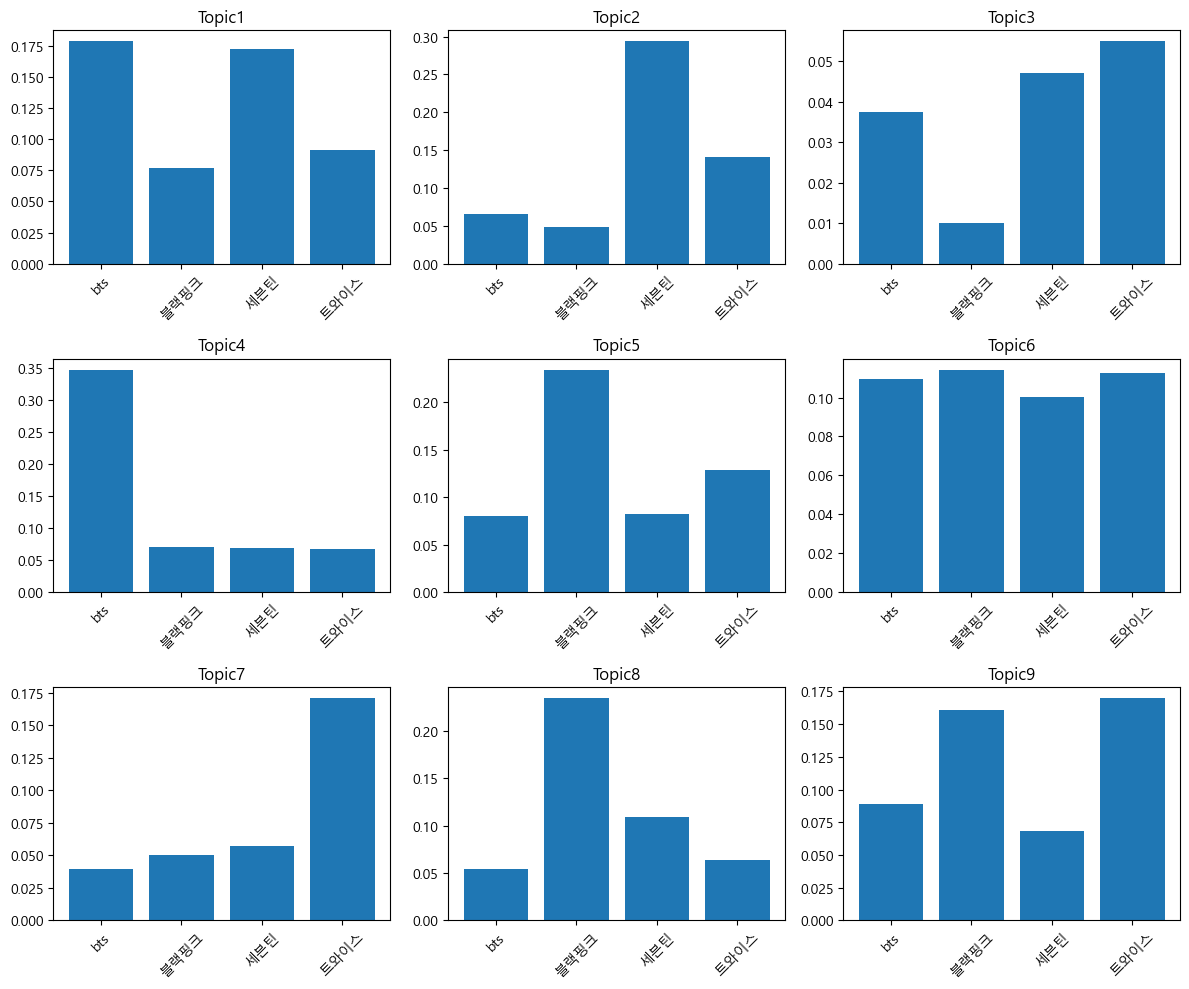

In [53]:
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
plt.rc('font', family='Malgun Gothic')

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for col, ax in zip(trend.columns.tolist(), axes.ravel()):
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)
    ax.bar(trend.index, trend[col])
for ax in axes.ravel()[num_topics:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

In [50]:
model.print_topics(num_words=10)

[(0,
  '0.016*"tour" + 0.015*"ticket" + 0.012*"award" + 0.009*"world" + 0.009*"concert" + 0.007*"good" + 0.006*"artist" + 0.006*"pm" + 0.006*"billboard" + 0.005*"hit"'),
 (1,
  '0.008*"love" + 0.007*"korean" + 0.007*"track" + 0.005*"south" + 0.005*"work" + 0.005*"world" + 0.005*"performance" + 0.005*"debut" + 0.005*"korea" + 0.004*"scoups"'),
 (2,
  '0.013*"love" + 0.009*"mina" + 0.006*"fashion" + 0.005*"seungkwan" + 0.004*"track" + 0.004*"good" + 0.004*"jeongyeon" + 0.004*"day" + 0.004*"company" + 0.003*"south"'),
 (3,
  '0.009*"south" + 0.009*"korean" + 0.008*"korea" + 0.007*"military" + 0.007*"jin" + 0.006*"world" + 0.006*"tour" + 0.006*"big" + 0.005*"service" + 0.004*"hit"'),
 (4,
  '0.027*"chart" + 0.015*"billboard" + 0.013*"debut" + 0.010*"world" + 0.010*"week" + 0.009*"artist" + 0.008*"sale" + 0.007*"act" + 0.007*"ddu" + 0.007*"du"'),
 (5,
  '0.010*"post" + 0.008*"entertainment" + 0.008*"artist" + 0.006*"korean" + 0.006*"star" + 0.005*"agency" + 0.005*"test" + 0.005*"statement" 